# MCDI505 · Semana 4 — Evaluación final en 2024 (anexo del informe)
**Estudiante:** Roberto Moncada · **Archivo:** `mcdi505_s4rmoncada.ipynb` · **Fecha:** octubre de 2026

**Cambios respecto de la plantilla:** se utilizaron los datos de *consumo_electrico_litoral_depurado_s4.csv*; el pronóstico puntual se calculó con la media corregida por sesgo, siguiendo el mismo criterio usado en las Sumativas 2 y 3 según la retroalimentación del profesor; además, se incluyeron cuatro secciones de apoyo para el informe: una tabla con los modelos evaluados, el cálculo del volumen a contratar, su sensibilidad a la razón de costos y notas de apoyo para el informe de la Sumativa 4.

## 0. Configuración y datos

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from scipy import stats
warnings.filterwarnings("ignore")
SEMILLA = 505
np.random.seed(SEMILLA)

In [2]:
# ==============================================================================
# Funciones de apoyo (las mismas de la Sesión 3, más tres envoltorios para DEL)
# No necesita modificarlas.
# ==============================================================================

def calcular_exponente_hurst(serie, min_ventana=8, max_ventana=None, n_ventanas=10):
    """Exponente de Hurst por Rango Reescalado (R/S). Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    if max_ventana is None:
        max_ventana = n // 4
    ventanas = np.unique(np.geomspace(min_ventana, max_ventana, num=n_ventanas, dtype=int))
    rs_promedio, ventanas_validas = [], []
    for w in ventanas:
        m = n // w
        if m < 1:
            continue
        rs_bloques = []
        for i in range(m):
            bloque = serie[i * w:(i + 1) * w]
            recorrido = np.cumsum(bloque - np.mean(bloque))
            desviacion = np.std(bloque)
            if desviacion > 0:
                rs_bloques.append((np.max(recorrido) - np.min(recorrido)) / desviacion)
        if rs_bloques:
            rs_promedio.append(np.mean(rs_bloques))
            ventanas_validas.append(w)
    pendiente, _ = np.polyfit(np.log(ventanas_validas), np.log(rs_promedio), 1)
    return pendiente


def aplicar_filtro_fraccional(serie, d):
    """Operador (1-B)^d. d > 0 diferencia fraccionalmente; d < 0 integra. Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    pesos = np.zeros(n)
    pesos[0] = 1.0
    for k in range(1, n):
        pesos[k] = pesos[k - 1] * (k - 1 - d) / k
    return np.array([np.sum(pesos[:t + 1] * serie[t::-1]) for t in range(n)])


def garch_log_verosimilitud_negativa(parametros, serie):
    """Log-verosimilitud negativa de un GARCH(1,1) gaussiano. Ver Sesión 3, §3.4."""
    omega, alpha, beta = parametros
    sigma2 = np.zeros(len(serie))
    sigma2[0] = np.var(serie)
    for t in range(1, len(serie)):
        sigma2[t] = omega + alpha * serie[t - 1] ** 2 + beta * sigma2[t - 1]
    if np.any(sigma2 <= 1e-8):
        return 1e10
    return 0.5 * np.sum(np.log(2 * np.pi) + np.log(sigma2) + serie ** 2 / sigma2)


def correccion_arfima(residuos, d, h):
    """Pronóstico h pasos del componente ARFIMA(0,d,0) de los residuos.

    Diferencia fraccionalmente los residuos con d, pronostica cero (ruido blanco)
    y vuelve a integrar con -d. Lo que queda es la persistencia que la memoria
    larga añadiría al pronóstico del SARIMA (en escala logarítmica).
    """
    r = np.asarray(residuos, dtype=float)
    extendida = np.concatenate([aplicar_filtro_fraccional(r, d), np.zeros(h)])
    return aplicar_filtro_fraccional(extendida, -d)[len(r):]


def estimar_garch11(residuos, h):
    """Estima un GARCH(1,1) por MLE sobre los residuos estandarizados.

    Devuelve un diccionario con omega, alpha, beta, persistencia, convergencia,
    residuos estandarizados por sigma_t y el factor de escala de la desviación
    estándar condicional para los h meses siguientes (1 = igual a la varianza
    incondicional).
    """
    r = np.asarray(residuos, dtype=float)
    s = r.std()
    u = r / s
    res = minimize(garch_log_verosimilitud_negativa, x0=[0.05, 0.10, 0.80], args=(u,),
                   bounds=[(1e-6, 5.0), (1e-6, 0.999), (1e-6, 0.999)],
                   constraints=({"type": "ineq", "fun": lambda p: 0.999 - p[1] - p[2]},),
                   method="SLSQP")
    om, al, be = res.x
    sigma2 = np.zeros(len(u)); sigma2[0] = u.var()
    for t in range(1, len(u)):
        sigma2[t] = om + al * u[t - 1] ** 2 + be * sigma2[t - 1]
    futura = np.zeros(h)
    futura[0] = om + al * u[-1] ** 2 + be * sigma2[-1]
    for i in range(1, h):
        futura[i] = om + (al + be) * futura[i - 1]
    incondicional = om / (1 - al - be)
    return {"omega": om, "alpha": al, "beta": be, "persistencia": al + be,
            "convergencia": bool(res.success),
            "residuos_estandarizados": u / np.sqrt(sigma2),
            "escala_futura": np.sqrt(futura / incondicional)}


def metricas(real, pred):
    """RMSE y MAE en la escala de los datos (GWh)."""
    e = np.asarray(real, float) - np.asarray(pred, float)
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e)))}


def cobertura_y_ancho(real, inferior, superior):
    """Proporción de meses dentro del intervalo y ancho promedio del intervalo (GWh)."""
    real, inferior, superior = (np.asarray(x, float) for x in (real, inferior, superior))
    return {"Cobertura": float(np.mean((real >= inferior) & (real <= superior))),
            "Ancho medio": float(np.mean(superior - inferior))}

In [3]:
df = pd.read_csv("consumo_electrico_litoral_depurado_s4.csv", parse_dates=["fecha"], index_col="fecha")
df.index.freq = "MS"
y = df["consumo_gwh"]
log_y = np.log(y)
print(f"Serie: {y.index[0]:%Y-%m} a {y.index[-1]:%Y-%m} ({len(y)} meses) · covid = 1 en {int(df['covid'].sum())} meses")

Serie: 2015-01 a 2024-12 (120 meses) · covid = 1 en 22 meses


In [4]:
# ==============================================================================
# COMPLETE: el modelo SARIMA que seleccionó en la Sumativa 2 (misma especificación)
# ==============================================================================
# Sumativas 2 y 3: modelo B, SARIMA(0,1,1)(0,1,1)12 sobre el logaritmo del consumo, con la indicadora covid
ORDEN = (0, 1, 1)                  # (p, d, q)
ORDEN_ESTACIONAL = (0, 1, 1, 12)   # (P, D, Q, s)
USAR_COVID = True                  # indicadora covid (mar-2020 a dic-2021) como variable exógena

assert ORDEN is not None and ORDEN_ESTACIONAL is not None, "Complete ORDEN y ORDEN_ESTACIONAL con su modelo de la Sumativa 2."

# COMPLETE solo si en la Sumativa 3 su modelo final incorporó componentes avanzados
D_FRACCIONAL = None       # la Sumativa 3 concluyó que no hay memoria larga: el modelo final no lleva ARFIMA
BANDAS_GARCH = False      # la Sumativa 3 concluyó que no hay volatilidad condicional: sin bandas GARCH

# Agregado (feedback del profesor): pronóstico puntual con la media corregida por sesgo, exp(μ + σ²/2),
# igual que en las Sumativas 2 y 3, para que las métricas sean comparables entre semanas.
# Los límites del intervalo (cuantiles) se retransforman con exp() sin corrección.
CORRECCION_SESGO = True

In [5]:
def ajustar_y_pronosticar(fin_entrenamiento, inicio_prueba, fin_prueba):
    """Ajusta el modelo final hasta `fin_entrenamiento` y pronostica el periodo de prueba en GWh."""
    lt = log_y[:fin_entrenamiento]
    h = len(log_y[inicio_prueba:fin_prueba])
    Xt = df[["covid"]][:fin_entrenamiento] if USAR_COVID else None
    Xp = df[["covid"]].loc[inicio_prueba:fin_prueba] if USAR_COVID else None
    m = SARIMAX(lt, exog=Xt, order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False)
    inicio = ORDEN[1] + ORDEN_ESTACIONAL[1] * ORDEN_ESTACIONAL[3]
    resid = m.resid.iloc[inicio:]
    p = m.get_forecast(h, exog=Xp)
    media = p.predicted_mean.to_numpy()
    sd = ((p.conf_int(alpha=0.05).iloc[:, 1] - p.predicted_mean) / 1.96).to_numpy()
    if D_FRACCIONAL is not None:
        media = media + correccion_arfima(resid, D_FRACCIONAL, h)
    if BANDAS_GARCH:
        sd = sd * estimar_garch11(resid, h)["escala_futura"]
    puntual = media + sd ** 2 / 2 if CORRECCION_SESGO else media      # media corregida por sesgo (ver configuración)
    return np.exp(puntual), np.exp(media - 1.96 * sd), np.exp(media + 1.96 * sd)


def evaluar(fin_entrenamiento, inicio_prueba, fin_prueba):
    """Métricas del modelo final y del naive estacional sobre el periodo de prueba."""
    real = y[inicio_prueba:fin_prueba].to_numpy()
    pred, inf, sup = ajustar_y_pronosticar(fin_entrenamiento, inicio_prueba, fin_prueba)
    naive = y.shift(12)[inicio_prueba:fin_prueba].to_numpy()
    y_ent = y[:fin_entrenamiento]
    escala_mase = float((y_ent - y_ent.shift(12)).dropna().abs().mean())   # MAE del naive estacional en entrenamiento
    filas = {}
    for nombre, p in [("Modelo final", pred), ("Naive estacional", naive)]:
        m = metricas(real, p)
        m["MASE"] = float(np.mean(np.abs(real - p)) / escala_mase)
        filas[nombre] = m
    tabla = pd.DataFrame(filas).T
    tabla["Cobertura IC 95 %"] = [cobertura_y_ancho(real, inf, sup)["Cobertura"], np.nan]
    return tabla, pred, inf, sup

## 1. Evaluación en validación 2023 y en prueba 2024

In [6]:
tabla_2023, *_ = evaluar("2022-12", "2023-01", "2023-12")
tabla_2024, pred24, inf24, sup24 = evaluar("2023-12", "2024-01", "2024-12")

resumen = pd.concat({"Validación 2023": tabla_2023, "Prueba 2024": tabla_2024})
print("Tabla 1. Modelo final frente al naive estacional: validación 2023 y prueba 2024 (RMSE y MAE en GWh)")
print(resumen.round(3).to_string())
print("\nPronóstico puntual con media corregida por sesgo" if CORRECCION_SESGO else "\nPronóstico puntual con exp(μ) (mediana)")
err24 = y["2024"].to_numpy() - pred24
print(f"Prueba 2024: sesgo medio = {err24.mean():+.2f} GWh ({100 * err24.mean() / y['2024'].mean():+.1f} % del consumo medio, "
      f"{y['2024'].mean():.2f} GWh) | meses con error positivo = {(err24 > 0).sum()}/12 | "
      f"meses dentro del IC 95 % = {int(((y['2024'] >= inf24) & (y['2024'] <= sup24)).sum())}/12 | "
      f"ancho medio del IC = {np.mean(sup24 - inf24):.1f} GWh")
print(f"Consumo medio mensual 2023 = {y['2023'].mean():.2f} GWh")

Tabla 1. Modelo final frente al naive estacional: validación 2023 y prueba 2024 (RMSE y MAE en GWh)
                                   RMSE    MAE   MASE  Cobertura IC 95 %
Validación 2023 Modelo final      6.854  6.398  0.983                1.0
                Naive estacional  7.263  6.528  1.003                NaN
Prueba 2024     Modelo final      4.866  3.998  0.614                1.0
                Naive estacional  8.193  6.666  1.024                NaN

Pronóstico puntual con media corregida por sesgo
Prueba 2024: sesgo medio = +2.89 GWh (+2.4 % del consumo medio, 120.05 GWh) | meses con error positivo = 9/12 | meses dentro del IC 95 % = 12/12 | ancho medio del IC = 29.7 GWh
Consumo medio mensual 2023 = 113.66 GWh


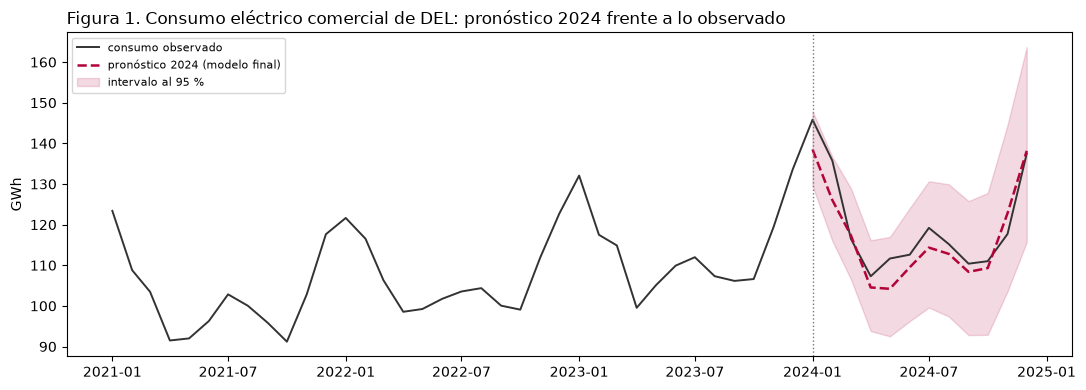

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y["2021-01":"2024-12"].index, y["2021-01":"2024-12"], color="#333333", lw=1.4, label="consumo observado")
ax.plot(y["2024"].index, pred24, color="#b30338", lw=1.8, ls="--", label="pronóstico 2024 (modelo final)")
ax.fill_between(y["2024"].index, inf24, sup24, color="#b30338", alpha=0.15, label="intervalo al 95 %")
ax.axvline(pd.Timestamp("2024-01-01"), color="#777777", ls=":", lw=1)
ax.set_title("Figura 1. Consumo eléctrico comercial de DEL: pronóstico 2024 frente a lo observado", loc="left")
ax.set_ylabel("GWh"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

**Lectura de la evaluación 2023 y 2024 (§1)**

El modelo superó al método naive, especialmente en 2024 (MASE = 0,61), con un error cerca de 40 % menor. El naive falló porque el consumo medio mensual aumentó de 113,66 GWh en 2023 a 120,05 GWh en 2024 (≈ 5,6 %), por lo que tendió a subestimar la demanda.

El sesgo se redujo de +6,40 GWh en 2023 (Semana 3) a +2,89 GWh en 2024 (2,4 % del consumo), probablemente por la incorporación de 2023 al entrenamiento.

La Figura 1 resume los principales resultados, con el pronóstico de 2024 y un intervalo que cubrió los 12 meses observados.

En conclusión, el modelo mejora al método naive: por poco en 2023 (MASE 0,98) y con claridad en 2024 (MASE 0,61), un año en que la demanda creció. Aun así, sigue subestimando 9 de 12 meses y su intervalo es ancho (29,7 GWh). Su buen desempeño y cobertura sugieren que es una herramienta adecuada para apoyar la planificación del consumo eléctrico.

## 2. Tabla de modelos para el informe

In [8]:
# ==============================================================================
# Tabla de modelos para el informe (Formativa 4, criterio 2): modelo final, alternativas descartadas
# en las semanas 2 y 3, y naive estacional, en la validación 2023 y en la prueba 2024
# ==============================================================================
def pronostico_spec(orden, orden_est, fin_ent, ini, fin, arfima=False, garch=False):
    """Igual que ajustar_y_pronosticar, pero para cualquier especificación; d del ARFIMA se reestima con Hurst (R/S)."""
    lt = log_y[:fin_ent]
    h = len(log_y[ini:fin])
    m = SARIMAX(lt, exog=df[["covid"]][:fin_ent], order=orden, seasonal_order=orden_est).fit(disp=False)
    resid = m.resid.iloc[orden[1] + orden_est[1] * orden_est[3]:]
    p = m.get_forecast(h, exog=df[["covid"]].loc[ini:fin])
    media = p.predicted_mean.to_numpy()
    sd = ((p.conf_int(alpha=0.05).iloc[:, 1] - p.predicted_mean) / 1.96).to_numpy()
    d = np.nan
    if arfima:
        d = calcular_exponente_hurst(resid) - 0.5
        media = media + correccion_arfima(resid, d, h)
    if garch:
        sd = sd * estimar_garch11(resid, h)["escala_futura"]
    puntual = media + sd ** 2 / 2 if CORRECCION_SESGO else media
    return np.exp(puntual), np.exp(media - 1.96 * sd), np.exp(media + 1.96 * sd), d

MODELOS = {
    "B. SARIMA(0,1,1)(0,1,1)12 + covid (final)": dict(orden=(0, 1, 1), orden_est=(0, 1, 1, 12)),
    "A. SARIMA(0,1,0)(0,1,1)12 + covid (S2: descartado por Ljung-Box)": dict(orden=(0, 1, 0), orden_est=(0, 1, 1, 12)),
    "B + ARFIMA(0,d,0) (S3: sin memoria larga)": dict(orden=(0, 1, 1), orden_est=(0, 1, 1, 12), arfima=True),
    "B + bandas GARCH(1,1) (S3: sin volatilidad)": dict(orden=(0, 1, 1), orden_est=(0, 1, 1, 12), garch=True),
}
filas = []
for periodo, (fin_ent, ini, fin) in {"Validación 2023": ("2022-12", "2023-01", "2023-12"),
                                     "Prueba 2024": ("2023-12", "2024-01", "2024-12")}.items():
    real = y[ini:fin].to_numpy()
    y_ent = y[:fin_ent]
    escala = float((y_ent - y_ent.shift(12)).dropna().abs().mean())
    for nombre, spec in MODELOS.items():
        pred, inf, sup, d = pronostico_spec(fin_ent=fin_ent, ini=ini, fin=fin, **spec)
        m = metricas(real, pred)
        filas.append({"periodo": periodo, "modelo": nombre, **m, "MASE": m["MAE"] / escala,
                      **cobertura_y_ancho(real, inf, sup), "d (ARFIMA)": d})
    naive = y.shift(12)[ini:fin].to_numpy()
    m = metricas(real, naive)
    filas.append({"periodo": periodo, "modelo": "Naive estacional (referencia)", **m, "MASE": m["MAE"] / escala,
                  "Cobertura": np.nan, "Ancho medio": np.nan, "d (ARFIMA)": np.nan})
tabla_modelos = pd.DataFrame(filas).set_index(["periodo", "modelo"])
print("Tabla 2. Modelos en la validación 2023 y en la prueba 2024 (RMSE, MAE y ancho en GWh; MASE < 1 = mejor que el naive estacional)")
print(tabla_modelos.round(3).to_string())

Tabla 2. Modelos en la validación 2023 y en la prueba 2024 (RMSE, MAE y ancho en GWh; MASE < 1 = mejor que el naive estacional)
                                                                                   RMSE    MAE   MASE  Cobertura  Ancho medio  d (ARFIMA)
periodo         modelo                                                                                                                   
Validación 2023 B. SARIMA(0,1,1)(0,1,1)12 + covid (final)                         6.854  6.398  0.983        1.0       29.445         NaN
                A. SARIMA(0,1,0)(0,1,1)12 + covid (S2: descartado por Ljung-Box)  7.347  6.919  1.064        1.0       35.268         NaN
                B + ARFIMA(0,d,0) (S3: sin memoria larga)                         7.063  6.643  1.021        1.0       29.387       0.152
                B + bandas GARCH(1,1) (S3: sin volatilidad)                       6.855  6.399  0.984        1.0       29.328         NaN
                Naive estacional (referencia

**¿Por qué se eligió el modelo final?**

El modelo B fue elegido porque tuvo el menor error en 2023 (empatado con su versión con bandas GARCH, que utiliza el mismo pronóstico puntual) y, en 2024, obtuvo resultados prácticamente iguales a los de las demás alternativas, con diferencias de 0,03 GWh o menos. Con solo 12 meses de evaluación, esas diferencias no son relevantes, y el MASE lo confirma: todas las alternativas quedan entre 0,61 y 0,62.

Cuando los resultados son tan parecidos, se prefiere el modelo más simple y que cumple correctamente los diagnósticos. En este caso, B tiene residuos sin autocorrelación y no incorpora parámetros adicionales que la evidencia no justifica.

Además, la alternativa A genera un intervalo de predicción cerca de 30 % más ancho (38,5 frente a 29,7 GWh), lo que implica mayor incertidumbre para la planificación y contratación de energía.

**Cadena de evidencia**

La selección del modelo siguió una secuencia clara: se aplicó la transformación logarítmica y la diferenciación d = 1 y D = 1, confirmadas por ADF = −8,82 (frente al valor crítico −2,90; Dickey y Fuller, 1979) y KPSS = 0,040 (frente a 0,463; Kwiatkowski et al., 1992). Luego se evaluaron 7 candidatos y se seleccionó el modelo B (S2). Posteriormente, se verificó que no hubiera memoria larga (H = 0,652, compatible con ruido blanco) ni volatilidad condicional (ARCH-LM p = 0,639; S3), y finalmente se validó su desempeño con la prueba de 2024 (MASE 0,61, S4).

## 3. Del pronóstico al volumen a contratar

In [9]:
# ==============================================================================
# Del pronóstico al volumen a contratar (Formativa 4, criterio 3)
# Caso transversal, sección 3: contratar de menos obliga a comprar en el spot a 2-4 veces el precio contratado.
# Notebook de la Semana 2, §8: con costo de quedarse corto c_u y de sobrar c_o, el volumen óptimo es el
# cuantil q* = c_u / (c_u + c_o) de la distribución predictiva (cuantiles: exp(μ + z·σ), sin corrección).
# ==============================================================================
def cuantil(media_log, sd_log, q):
    return np.exp(media_log + stats.norm.ppf(q) * sd_log)

def pronostico_log(fin_ent, ini, fin):
    m = SARIMAX(log_y[:fin_ent], exog=df[["covid"]][:fin_ent], order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False)
    p = m.get_forecast(len(log_y[ini:fin]), exog=df[["covid"]].loc[ini:fin])
    return p.predicted_mean.to_numpy(), np.sqrt(np.asarray(p.var_pred_mean))

# (a) Prueba retrospectiva en 2024: ¿cuánto habría costado contratar cada volumen? (costo en GWh-equivalentes)
mu24, sd24 = pronostico_log("2023-12", "2024-01", "2024-12")
real24 = y["2024"].to_numpy()
filas_c = []
for k in (2, 3, 4):                                    # el spot cuesta k veces el contrato: c_u = k · c_o
    q = k / (k + 1)
    for etiqueta, vol in [("media corregida", np.exp(mu24 + sd24 ** 2 / 2)), (f"cuantil {q:.0%}", cuantil(mu24, sd24, q))]:
        corto = np.clip(real24 - vol, 0, None).sum()
        sobra = np.clip(vol - real24, 0, None).sum()
        filas_c.append({"c_u / c_o": k, "volumen": etiqueta, "contratado 2024 (GWh)": vol.sum(),
                        "faltó (GWh)": corto, "sobró (GWh)": sobra, "costo relativo": k * corto + sobra,
                        "meses cortos": int((real24 > vol).sum())})
tabla_costo = pd.DataFrame(filas_c).set_index(["c_u / c_o", "volumen"])
print(f"Tabla 3. Prueba retrospectiva 2024 (consumo real: {real24.sum():.1f} GWh). Costo relativo = c_u/c_o · faltante + sobrante")
print(tabla_costo.round(1).to_string())

# (b) Plan para los próximos 12 meses: una vez evaluado, el modelo se reestima con 2015-2024 (Semana 2, §8)
idx25 = pd.date_range("2025-01-01", periods=12, freq="MS")
m_full = SARIMAX(log_y, exog=df[["covid"]], order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False)
p25 = m_full.get_forecast(12, exog=pd.DataFrame({"covid": np.zeros(12)}, index=idx25))
mu25, sd25 = p25.predicted_mean.to_numpy(), np.sqrt(np.asarray(p25.var_pred_mean))
Q_STAR = 0.75                                          # c_u = 3 · c_o (valor central del rango 2-4 del caso)
plan = pd.DataFrame({"media corregida": np.exp(mu25 + sd25 ** 2 / 2),
                     "IC 95 % inferior": np.exp(mu25 - 1.96 * sd25), "IC 95 % superior": np.exp(mu25 + 1.96 * sd25),
                     "cuantil 67 %": cuantil(mu25, sd25, 2 / 3), "cuantil 75 % (a contratar)": cuantil(mu25, sd25, Q_STAR),
                     "cuantil 80 %": cuantil(mu25, sd25, 0.80)}, index=idx25.strftime("%Y-%m"))
print("\nTabla 4. Plan 2025 (GWh), modelo reestimado con 2015-2024")
print(plan.round(1).to_string())
print(f"Total 2025: media {plan['media corregida'].sum():.1f} GWh · cuantil 75 % {plan['cuantil 75 % (a contratar)'].sum():.1f} GWh "
      f"(+{100 * (plan['cuantil 75 % (a contratar)'].sum() / plan['media corregida'].sum() - 1):.1f} % sobre la media) · "
      f"coeficientes: ma.L1 = {m_full.params['ma.L1']:.3f}, ma.S.L12 = {m_full.params['ma.S.L12']:.3f}")

Tabla 3. Prueba retrospectiva 2024 (consumo real: 1440.6 GWh). Costo relativo = c_u/c_o · faltante + sobrante
                           contratado 2024 (GWh)  faltó (GWh)  sobró (GWh)  costo relativo  meses cortos
c_u / c_o volumen                                                                                       
2         media corregida                 1405.9         41.3          6.7            89.3             9
          cuantil 67%                     1442.4         20.1         22.0            62.3             6
3         media corregida                 1405.9         41.3          6.7           130.6             9
          cuantil 75%                     1465.4         13.8         38.6            79.8             3
4         media corregida                 1405.9         41.3          6.7           171.9             9
          cuantil 80%                     1481.4         10.9         51.7            95.5             3



Tabla 4. Plan 2025 (GWh), modelo reestimado con 2015-2024
         media corregida  IC 95 % inferior  IC 95 % superior  cuantil 67 %  cuantil 75 % (a contratar)  cuantil 80 %
2025-01            142.3             133.1             152.1         144.4                       145.6         146.4
2025-02            129.8             119.7             140.6         132.0                       133.4         134.3
2025-03            119.9             109.2             131.4         122.2                       123.6         124.6
2025-04            107.1              96.5             118.6         109.4                       110.9         111.8
2025-05            107.3              95.7             119.9         109.8                       111.3         112.4
2025-06            112.2              99.2             126.5         115.1                       116.8         118.0
2025-07            117.4             102.9             133.4         120.5                       122.5         123.8
2025-

**Del pronóstico al volumen a contratar (§3, criterio 3)**

DEL necesita decidir cuánta energía contratar. Si contrata de menos, debe comprar en el mercado spot, que puede costar entre 2 y 4 veces más que un contrato. Por eso se recomienda contratar un cuantil superior en lugar de la media: 67 % (relación 2:1), 75 % (3:1) y 80 % (4:1), según la regla del vendedor de diarios, q* = c_u / (c_u + c_o) (Arrow et al., 1951; Universidad Andrés Bello, s. f.-b).

**La prueba retrospectiva de 2024** (Tabla 3) mostró que contratar la media generó faltantes de 41,3 GWh en 9 de 12 meses, con un costo relativo de 130,6. En cambio, el cuantil 75 % redujo los faltantes a 13,8 GWh en 3 meses y disminuyó el costo a 79,8, cerca de 39 % menos.

**Plan 2025**

Con el modelo reestimado (2015-2024), la proyección para 2025 es de 1.440,7 GWh en la media y 1.499,3 GWh en el cuantil 75 % (+4,1 %; Tabla 4). Los meses de mayor volumen a contratar (cuantil 75 %) son diciembre (148,8 GWh) y enero (145,6 GWh); en consumo esperado (media), enero (142,3 GWh) y diciembre (141,1 GWh).

**Limitaciones**

- **Solo 12 meses de prueba:** los resultados se basan únicamente en 2024.
- **Costo supuesto:** la relación 3:1 puede variar; si cambia a 2:1 o a 4:1, el cuantil óptimo pasa a 67 % o a 80 %, respectivamente (Tabla 5).
- **Eventos extremos:** los residuos no fueron normales (Jarque-Bera p = 0,001, Semana 2; Jarque y Bera, 1987), por lo que los cuantiles podrían subestimar algunos meses atípicos.
- **Posibles cambios futuros:** el parámetro MA estacional (−0,970) sugiere una estacionalidad muy estable, por lo que cambios importantes en el patrón de consumo podrían no reflejarse bien en el modelo.
- **Variables omitidas:** el modelo considera COVID, pero no incluye temperatura ni número de clientes.

### 3.1 Sensibilidad del cuantil a la razón de costos

Agregado por la retroalimentación del profesor a la Formativa 4. Regla del vendedor de diarios: $q^* = c_u / (c_u + c_o)$ (Arrow et al., 1951; Gneiting, 2011).

In [10]:
# ==============================================================================
# Sensibilidad del cuantil a la razón de costos k = c_u / c_o (feedback del profesor a la Formativa 4)
# q* = k / (k + 1). Se mueve k dentro y fuera del rango 2-4 del caso y se mide, para cada k:
#   (a) el volumen 2025 con q* y cuánto supera a la media corregida;
#   (b) el costo esperado 2025 según la distribución predictiva log-normal del modelo, contratando
#       q*, el cuantil 75 % (la elección del informe, k = 3) o la media corregida;
#   (c) el costo real de la prueba retrospectiva 2024 (como en la Tabla 3) con q* y con la media.
# Costos en GWh-equivalentes de c_o, como en la Tabla 3.
# ==============================================================================
from scipy.optimize import brentq

def costo_esperado(vol, media_log, sd_log, k):
    """k·E[(Y − v)+] + E[(v − Y)+] con Y log-normal(μ, σ²), sumado sobre los 12 meses (fórmula cerrada)."""
    d2 = (media_log - np.log(vol)) / sd_log
    d1 = d2 + sd_log
    ey = np.exp(media_log + sd_log ** 2 / 2)
    falta = ey * stats.norm.cdf(d1) - vol * stats.norm.cdf(d2)       # E[(Y − v)+], faltante esperado
    sobra = vol * stats.norm.cdf(-d2) - ey * stats.norm.cdf(-d1)     # E[(v − Y)+], sobrante esperado
    return float(np.sum(k * falta + sobra))

def costo_real(vol, real, k):
    """Costo relativo observado: k · faltante + sobrante (igual que la Tabla 3)."""
    return float(k * np.clip(real - vol, 0, None).sum() + np.clip(vol - real, 0, None).sum())

media25 = np.exp(mu25 + sd25 ** 2 / 2)
media24 = np.exp(mu24 + sd24 ** 2 / 2)
v75_25 = cuantil(mu25, sd25, Q_STAR)
RAZONES = (1, 1.5, 2, 2.5, 3, 3.5, 4, 5, 6)                      # el caso da 2 a 4; se agregan extremos
filas_s = []
for k in RAZONES:
    q = k / (k + 1)
    vq = cuantil(mu25, sd25, q)
    ce_q, ce_75, ce_m = (costo_esperado(v, mu25, sd25, k) for v in (vq, v75_25, media25))
    cr_q, cr_m = costo_real(cuantil(mu24, sd24, q), real24, k), costo_real(media24, real24, k)
    filas_s.append({"k = c_u/c_o": k, "q* (%)": 100 * q, "vol. 2025 q*": vq.sum(),
                    "sobre media (%)": 100 * (vq.sum() / media25.sum() - 1),
                    "esp. 2025 q*": ce_q, "esp. 2025 75 %": ce_75, "esp. 2025 media": ce_m,
                    "sobrecosto 75 % (%)": 100 * (ce_75 / ce_q - 1), "sobrecosto media (%)": 100 * (ce_m / ce_q - 1),
                    "real 2024 q*": cr_q, "real 2024 media": cr_m, "ahorro 2024 (%)": 100 * (1 - cr_q / cr_m)})
tabla_sens = pd.DataFrame(filas_s).set_index("k = c_u/c_o")
print("Tabla 5. Sensibilidad del cuantil a la razón de costos (volúmenes en GWh; costos en GWh-equivalentes de c_o)")
print("  esp. = costo esperado 2025 según el modelo; real 2024 = costo de la prueba retrospectiva; "
      "sobrecosto = respecto de contratar q*")
with pd.option_context("display.width", 250):
    print(tabla_sens.round(1).to_string())
print(f"\nContratar el 75 % (k = 3): 2025 = {v75_25.sum():.1f} GWh. Si la razón real fuera 2 o 4, el sobrecosto esperado sería "
      f"{tabla_sens.loc[2, 'sobrecosto 75 % (%)']:.1f} % o {tabla_sens.loc[4, 'sobrecosto 75 % (%)']:.1f} %; "
      f"contratar la media costaría {tabla_sens.loc[2, 'sobrecosto media (%)']:.1f} % o {tabla_sens.loc[4, 'sobrecosto media (%)']:.1f} % más.")
k_cruce = brentq(lambda k: costo_esperado(v75_25, mu25, sd25, k) - costo_esperado(media25, mu25, sd25, k), 1.01, 3)
print(f"Punto de cruce: con k < {k_cruce:.2f}, contratar la media tiene menor costo esperado que contratar el cuantil 75 %.")


Tabla 5. Sensibilidad del cuantil a la razón de costos (volúmenes en GWh; costos en GWh-equivalentes de c_o)
  esp. = costo esperado 2025 según el modelo; real 2024 = costo de la prueba retrospectiva; sobrecosto = respecto de contratar q*
             q* (%)  vol. 2025 q*  sobre media (%)  esp. 2025 q*  esp. 2025 75 %  esp. 2025 media  sobrecosto 75 % (%)  sobrecosto media (%)  real 2024 q*  real 2024 media  ahorro 2024 (%)
k = c_u/c_o                                                                                                                                                                                 
1.0            50.0        1437.7             -0.2          71.3            87.4             71.3                 22.5                   0.1          48.9             48.0             -1.9
1.5            60.0        1460.5              1.4          87.0            94.6             89.2                  8.7                   2.5          54.4             68.6             20.7
2.0  

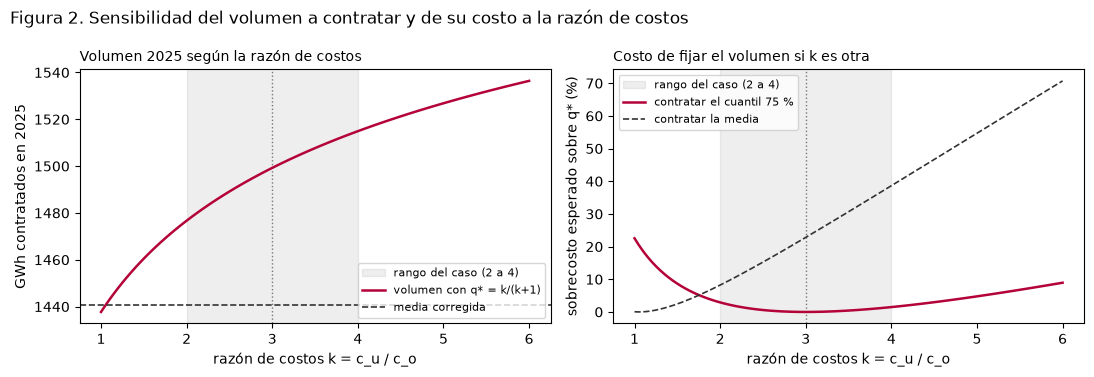

In [11]:
# Figura 2: volumen 2025 según k (izquierda) y sobrecosto esperado de fijar el 75 % o la media (derecha)
k_fino = np.linspace(1, 6, 101)
vol_fino = [cuantil(mu25, sd25, k / (k + 1)).sum() for k in k_fino]
sc75 = [100 * (costo_esperado(v75_25, mu25, sd25, k) / costo_esperado(cuantil(mu25, sd25, k / (k + 1)), mu25, sd25, k) - 1) for k in k_fino]
scm = [100 * (costo_esperado(media25, mu25, sd25, k) / costo_esperado(cuantil(mu25, sd25, k / (k + 1)), mu25, sd25, k) - 1) for k in k_fino]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for ax in (a1, a2):
    ax.axvspan(2, 4, color="#777777", alpha=0.12, label="rango del caso (2 a 4)")
    ax.axvline(3, color="#777777", ls=":", lw=1)
    ax.set_xlabel("razón de costos k = c_u / c_o")
a1.plot(k_fino, vol_fino, color="#b30338", lw=1.8, label="volumen con q* = k/(k+1)")
a1.axhline(media25.sum(), color="#333333", ls="--", lw=1.2, label="media corregida")
a1.set_ylabel("GWh contratados en 2025"); a1.set_title("Volumen 2025 según la razón de costos", loc="left", fontsize=10)
a1.legend(fontsize=8, loc="lower right")
a2.plot(k_fino, sc75, color="#b30338", lw=1.8, label="contratar el cuantil 75 %")
a2.plot(k_fino, scm, color="#333333", lw=1.2, ls="--", label="contratar la media")
a2.set_ylabel("sobrecosto esperado sobre q* (%)"); a2.set_title("Costo de fijar el volumen si k es otra", loc="left", fontsize=10)
a2.legend(fontsize=8, loc="upper left")
fig.suptitle("Figura 2. Sensibilidad del volumen a contratar y de su costo a la razón de costos", x=0.01, ha="left")
plt.tight_layout(); plt.show()


**Principales conclusiones Tabla 5 y figura 2**
- La recomendación del 75 % es robusta dentro del rango k = 2-4. Los resultados muestran que el nivel óptimo prácticamente no cambia en ese rango, por lo que la recomendación se mantiene cercana al 75 %.

- Sí, conviene reformular esa limitación. En vez de decir que el modelo "supone que el costo de quedarse corto es 3 veces mayor", es más claro explicar que esa decisión genera un sobrecosto estimado entre 1,5 % y 2,9 %, una cifra más fácil de interpretar en términos prácticos.

- La recomendación cambiaría si la relación de precios spot bajara de k < 1,75. En ese escenario, el costo de quedarse corto sería relativamente menor y el nivel recomendado de cobertura disminuiría.


## 4. Notas para el informe

**1. Problema, metodología y solución:**

Decisión: elegir cuánta energía contratar para el año siguiente. Si se contrata menos de lo necesario, hay que comprar energía en el mercado spot, donde el precio puede ser entre 2 y 4 veces más alto. Si se contrata de más, se termina pagando energía que no se utiliza.

Para apoyar esta decisión, se analizaron 10 años de consumo mensual (2015-2024) con un modelo que reconoce la estacionalidad anual y el efecto de la pandemia. En 2024, ese modelo se equivocó en promedio unos 4 GWh por mes (3,3 %), cerca de 40 % menos que repetir el consumo del año anterior (Figura 1). La propuesta es contratar un volumen algo mayor que el pronóstico (alrededor de 4 % más), porque quedarse corto cuesta más que sobrar.

**2. Frase de por qué se eligió el modelo final:**

**Tabla 2 (§2).** El modelo tuvo el menor error en 2023 (RMSE 6,85 GWh) y, en 2024, obtuvo resultados similares a los de alternativas más complejas. También logró ese desempeño sin necesidad de usar intervalos más anchos y fue el único candidato de la Semana 2 que, además de superar al naive, pasó la prueba de Ljung-Box.

**3. Recomendación principal (con su cifra) y limitación más importante:**

**Contratar el cuantil 75 %**, equivalente a 1.499,3 GWh para 2025, lo que representa un 4,1 % más que el consumo promedio esperado. Con esta estrategia, en 2024 el costo habría sido aproximadamente 39 % menor.

Como limitación, este resultado supone que el costo de quedarse corto es 3 veces mayor que el de contratar de más y se basa en una prueba de solo 12 meses.

### Referencias (APA 7)

Propuesta con las fuentes que ya citan los textos o las correcciones 2 a 5. DOI de Arrow et al. (1951) y Gneiting (2011) verificados en Crossref. Dejar en el informe **solo las citadas**.

Arrow, K. J., Harris, T., y Marschak, J. (1951). Optimal inventory policy. *Econometrica, 19*(3), 250–272. https://doi.org/10.2307/1906813

Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics, 31*(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1

Box, G. E. P., Jenkins, G. M., Reinsel, G. C., y Ljung, G. M. (2015). *Time series analysis: Forecasting and control* (5.ª ed.). Wiley.

Dickey, D. A., y Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association, 74*(366a), 427–431. https://doi.org/10.1080/01621459.1979.10482531

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica, 50*(4), 987–1007. https://doi.org/10.2307/1912773

Gneiting, T. (2011). Quantiles as optimal point forecasts. *International Journal of Forecasting, 27*(2), 197–207. https://doi.org/10.1016/j.ijforecast.2009.12.015

Hurst, H. E. (1951). Long-term storage capacity of reservoirs. *Transactions of the American Society of Civil Engineers, 116*(1), 770–799.

Hyndman, R. J., y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Hyndman, R. J., y Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting, 22*(4), 679–688. https://doi.org/10.1016/j.ijforecast.2006.03.001

Jarque, C. M., y Bera, A. K. (1987). A test for normality of observations and regression residuals. *International Statistical Review, 55*(2), 163–172. https://doi.org/10.2307/1403192

Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., y Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root: How sure are we that economic time series have a unit root? *Journal of Econometrics, 54*(1–3), 159–178. https://doi.org/10.1016/0304-4076(92)90104-Y

Ljung, G. M., y Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika, 65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

Seabold, S., y Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Universidad Andrés Bello. (s. f.-a). *MCDI505 — Análisis de series de tiempo: Caso transversal del curso* [Material de curso]. UNAB Online.

Universidad Andrés Bello. (s. f.-b). *MCDI505 — Análisis de series de tiempo: Notebook de la Sesión 2 (metodología Box-Jenkins) y guía de compañía de la Semana 4* [Material de curso]. UNAB Online.

<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

### [BORRADOR] Correcciones «Dice / Debe decir» (2.ª ronda)

Cada «Dice» es texto literal del autor. Se aplican solo si el autor lo decide. Prioridad: **P1** afecta el puntaje o la concordancia con los resultados; P2 precisión; P3 forma.

**A. Conclusiones de la §3.1 y bloque 3**

| # | Celda | Dice | Debe decir | Por qué | Prioridad |
|---|---|---|---|---|---|
| 1 | §3.1, conclusiones | «Principales conclusiones Tabla 5 y figura 2» | «Principales conclusiones de la Tabla 5 y la Figura 2» | Artículos y mayúscula, como en «Figura 1» | P3 |
| 2 | §3.1, viñeta 1 | «Los resultados muestran que el nivel óptimo prácticamente no cambia en ese rango, por lo que la recomendación se mantiene cercana al 75 %.» | «Aunque el cuantil óptimo varía entre 66,7 % y 80 % (1.476,7 a 1.514,9 GWh), contratar el 75 % cuesta como máximo 2,9 % más que el óptimo, por lo que la recomendación se mantiene.» | La Tabla 5 muestra que q* **sí cambia** en el rango 2-4; lo que se mantiene estable es el **costo** de fijar el 75 % | **P1** |
| 3 | §3.1, viñeta 2 | «Sí, conviene reformular esa limitación. En vez de decir que el modelo "supone que el costo de quedarse corto es 3 veces mayor", es más claro explicar que esa decisión genera un sobrecosto estimado entre 1,5 % y 2,9 %, una cifra más fácil de interpretar en términos prácticos.» | «La limitación del costo supuesto puede expresarse en cifras: si la razón real fuera 4:1 o 2:1 en lugar de 3:1, contratar el 75 % generaría un sobrecosto esperado de 1,5 % o 2,9 %, respectivamente (Tabla 5).» | «Sí, conviene…» responde a una pregunta guía que ya no está en el notebook; falta decir **cuándo** ocurre el sobrecosto (si la razón real es 2 o 4) | P2 |
| 4 | §3.1, viñeta 3 | «si la relación de precios spot bajara de k < 1,75» | «si la razón de costos bajara de 1,75 (k < 1,75)» | «Bajara de k <» repite la comparación; k es la razón de costos c_u / c_o, no el precio spot | P2 |
| 5 | §3.1, viñeta 3 | «el nivel recomendado de cobertura disminuiría» | «el cuantil recomendado sería menor y contratar la media costaría menos que el 75 % (Tabla 5)» | «Cobertura» se confunde con la cobertura del IC 95 %; la salida de la Tabla 5 dice esto último | P3 |
| 6 | §4, bloque 3 | «Como limitación, este resultado supone que el costo de quedarse corto es 3 veces mayor que el de contratar de más y se basa en una prueba de solo 12 meses.» | «Como limitación, este resultado supone que el costo de quedarse corto es 3 veces mayor que el de contratar de más (si fuera 2 o 4 veces, el sobrecosto esperado sería de 2,9 % o 1,5 %; Tabla 5) y se basa en una prueba de solo 12 meses.» | La viñeta 2 propone reformular esta limitación, pero el bloque 3 no cambió | P2 |

**B. Referencias: 9 de las 15 entradas no se citan en el texto** (APA: la lista lleva solo lo citado)

| # | Celda | Dice | Debe decir | Prioridad |
|---|---|---|---|---|
| 7 | Referencias | «Propuesta con las fuentes que ya citan los textos o las correcciones 2 a 5. DOI de Arrow et al. (1951) y Gneiting (2011) verificados en Crossref. Dejar en el informe **solo las citadas**.» | *(eliminar el párrafo: es una nota del asistente)* | **P1** |
| 8 | §2, Cadena de evidencia | «(H = 0,652, compatible con ruido blanco)» | «(H = 0,652, compatible con ruido blanco; Hurst, 1951)» | P2 |
| 9 | §2, Cadena de evidencia | «(ARCH-LM p = 0,639; S3)» | «(ARCH-LM p = 0,639; S3; Engle, 1982)» | P2 |
| 10 | §2, Cadena de evidencia | «(MASE 0,61, S4)» | «(MASE 0,61, S4; Hyndman y Koehler, 2006)» | P2 |
| 11 | §4, bloque 2 | «pasó la prueba de Ljung-Box.» | «pasó la prueba de Ljung-Box (Ljung y Box, 1978).» | P2 |
| 12 | §2, ¿Por qué se eligió? | «se prefiere el modelo más simple y que cumple correctamente los diagnósticos.» | «se prefiere el modelo más simple y que cumple correctamente los diagnósticos (principio de parsimonia; Box et al., 2015).» | P2 |
| 13 | §3, párrafo 1 | «que puede costar entre 2 y 4 veces más que un contrato.» | «que puede costar entre 2 y 4 veces más que un contrato (Universidad Andrés Bello, s. f.-a).» | P2: sin esta cita, «s. f.-b» queda sin «s. f.-a» |
| 14 | Encabezado | «el pronóstico puntual se calculó con la media corregida por sesgo,» | «el pronóstico puntual se calculó con la media corregida por sesgo (Hyndman y Athanasopoulos, 2021, sección 5.6),» | P2 |
| 15 | Referencias | Entradas de Bollerslev (1986) y Seabold y Perktold (2010) | Eliminarlas, o citarlas donde corresponda (p. ej., «los modelos se estimaron con statsmodels (Seabold y Perktold, 2010)») | P3 |
| 16 | Referencias | «Box, G. E. P., Jenkins, G. M., Reinsel, G. C., y Ljung, G. M. (2015).» | Mantener 2015 (como en las Sumativas 2 y 3) o usar 2016 (como la guía de la S4), pero igual en el notebook y el informe | P3 |

**C. Declaración de uso de IA** (pendiente desde la 1.ª ronda)

| # | Dice | Debe decir | Prioridad |
|---|---|---|---|
| 17 | «Se utilizó como borrador y apoyo práctico para el código de las secciones, borrador de ideas y guías de interpretación.» | Describir con exactitud lo que hizo el asistente: programó las Tablas 2 a 5 y las Figuras 1 y 2 (incluida la sensibilidad de la §3.1), verificó las cifras, propuso preguntas guía para las conclusiones de la §3.1, correcciones «dice / debe decir» y la lista de referencias, y armó el PDF de la Formativa 4. El autor la redacta; si tiene dudas sobre el código hecho por la IA, consulta al docente | **P1** |
| 18 | «\| ¿En qué partes específicas? \|Se utilizó» | «\| ¿En qué partes específicas? \| Se utilizó» | P3 |

_Borrador del asistente: correcciones para que el autor decida. Las instrucciones de la Sumativa 4 no permiten que la IA produzca las respuestas. **Borrar esta celda antes de entregar.**_

</div>

## Declaración de uso de asistentes de IA

| Pregunta | Respuesta |
|---|---|
| ¿Utilizó asistentes de IA en esta entrega? | Sí. Se usó Claude (Anthropic), en Claude Code, como apoyo para entender, practicar y preparar un borrador de esta entrega. |
| ¿En qué partes específicas? |Se utilizó como borrador y apoyo práctico para el código de las secciones, borrador de ideas y guías de interpretación. Sin embargo, las interpretaciones finales y las conclusiones se realizaron mediante análisis propio para cada una de las secciones. |
| ¿Qué verificó de forma independiente y cómo? | Se ejecutó el notebook completo desde un kernel reiniciado en VS Code y se verificó que fuese autocontenido. Además, se revisó e interpretó cada resultado y se verificó que cada texto coincidiera con los valores de las tablas de resultados; posteriormente, se generó el PDF ejecutivo de esta entrega. Por último, se comprobó el trabajo con la rúbrica publicada antes de la entrega. |